<a href="https://colab.research.google.com/github/naminipla1920-ui/AH2179-Final_Project/blob/main/Specialized_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Specialized Model

## Section 0: Setup and fast load

Loads pre-computed data and trained models from Drive.

Loads:
  - Line 507 processed feature dataset
  - Reconstructed ServiceAlert incidents
  - Chronological train / validation / test split
  - Final selected specialized Random Forest
  - Exact saved feature list/order
  - Saved model metadata

In [ ]:
# ------------------------------------------------------------
# 0.1 Imports
# ------------------------------------------------------------
import os
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.cluster import (
    DBSCAN,
    KMeans
)

sns.set()

# ------------------------------------------------------------
# 0.2 Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")

# ------------------------------------------------------------
# 0.3 Project paths
# ------------------------------------------------------------

PROJECT_PATH = (
    "/content/drive/MyDrive/"
    "Project AI in Transportation"
)

ALERTS_PATH = (
    f"{PROJECT_PATH}/alerts_results"
)

MODELS_PATH = (
    f"{PROJECT_PATH}/models"
)

SPECIALIZED_MODEL_PATH = (
    f"{MODELS_PATH}/specialized"
)

LINE_ID = "9011001050700000"


# ------------------------------------------------------------
# 0.4 Load processed Line 507 data
# ------------------------------------------------------------

clean = pd.read_csv(
    f"{ALERTS_PATH}/line_{LINE_ID}_features.csv",
    low_memory=False
)

route_incidents = pd.read_csv(
    f"{ALERTS_PATH}/route_incidents.csv",
    low_memory=False
)

# Standardize dates immediately
clean["date"] = pd.to_datetime(
    clean["date"]
)

route_incidents["start"] = pd.to_datetime(
    route_incidents["start"],
    errors="coerce"
)

route_incidents["end"] = pd.to_datetime(
    route_incidents["end"],
    errors="coerce"
)

route_incidents["route_id"] = (
    route_incidents["route_id"]
    .astype(str)
)

print("Data loaded successfully.")
print("Line 507 dataset:", clean.shape)
print("ServiceAlert incidents:", route_incidents.shape)


# ------------------------------------------------------------
# 0.5 Load exact saved feature list
# ------------------------------------------------------------

features = joblib.load(
    f"{SPECIALIZED_MODEL_PATH}/"
    "line507_features.joblib"
)

target = "observed_arrival_delay"

print("\nSaved feature order:")
for i, feature in enumerate(features, start=1):
    print(f"{i:2d}. {feature}")


# ------------------------------------------------------------
# 0.6 Rebuild modeling dataset
# ------------------------------------------------------------

model_df = clean.dropna(subset=["upstream_delay"]).copy()

model_df = model_df.sort_values(["date", "trip_id", "stop_sequence"]).reset_index(drop=True)

# ------------------------------------------------------------
# 0.7 Rebuild chronological split
# ------------------------------------------------------------

# January–September: training
train_df = model_df[model_df['date'] < '2024-10-01'].copy()
# October: validation / model selection
val_df   = model_df[(model_df['date'] >= '2024-10-01') & (model_df['date'] < '2024-11-01')].copy()
# November–December: held-out final test
test_df  = model_df[model_df['date'] >= '2024-11-01'].copy()

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

X_test = test_df[features]
y_test = test_df[target]


print("\nChronological split:")
print(
    f"Train      Jan–Sep : "
    f"{len(train_df):,}"
)

print(
    f"Validation Oct    : "
    f"{len(val_df):,}"
)

print(
    f"Test       Nov–Dec: "
    f"{len(test_df):,}"
)


# ------------------------------------------------------------
# 0.8 Load final specialized model
# ------------------------------------------------------------

best_rf = joblib.load(
    f"{SPECIALIZED_MODEL_PATH}/"
    "line507_random_forest.joblib"
)

print(
    "\nFinal specialized Random Forest loaded."
)

print(best_rf)


# ------------------------------------------------------------
# 0.9 Load model metadata
# ------------------------------------------------------------

with open(
    f"{SPECIALIZED_MODEL_PATH}/"
    "line507_rf_model_info.json",
    "r"
) as f:

    specialized_model_info = json.load(f)

print("\nModel metadata loaded.")

print(
    "Selected using:",
    specialized_model_info[
        "selection_period"
    ]
)

print(
    "Stored validation MAE:",
    specialized_model_info[
        "validation_results"
    ]["MAE_seconds"],
    "s"
)


# ------------------------------------------------------------
# 0.10 Compatibility checks
# ------------------------------------------------------------

assert len(features) == best_rf.n_features_in_, (
    "Saved feature count does not match "
    "the Random Forest input dimension."
)

if hasattr(best_rf, "feature_names_in_"):

    assert list(
        best_rf.feature_names_in_
    ) == list(features), (
        "Feature order does not match the "
        "order used to train the Random Forest."
    )

assert not X_train[features].isna().any().any(), (
    "Training features contain missing values."
)

assert not X_val[features].isna().any().any(), (
    "Validation features contain missing values."
)

assert not X_test[features].isna().any().any(), (
    "Test features contain missing values."
)

print(
    "\nAll model/data compatibility checks passed."
)


# ------------------------------------------------------------
# 0.11 Verify restored model on October
# ------------------------------------------------------------

pred_rf_val = best_rf.predict(
    X_val
)

rf_val_mae = mean_absolute_error(
    y_val,
    pred_rf_val
)

rf_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        pred_rf_val
    )
)

rf_val_r2 = r2_score(
    y_val,
    pred_rf_val
)

print(
    "\nRandom Forest — October Validation"
)

print(
    f"MAE:  {rf_val_mae:.2f} s"
)

print(
    f"RMSE: {rf_val_rmse:.2f} s"
)

print(
    f"R²:   {rf_val_r2:.4f}"
)


# ------------------------------------------------------------
# 0.12 Ready
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("PROJECT STATE RESTORED SUCCESSFULLY")
print("=" * 55)

print("Final model : Specialized Random Forest")
print("Route       : Line 507")
print("Train       : January–September 2024")
print("Validation  : October 2024")
print("Held-out    : November–December 2024")
print("Scaler      : Not required")

Mounted at /content/drive
Data loaded successfully.
Line 507 dataset: (418125, 30)
ServiceAlert incidents: (5161, 8)

Saved feature order:
 1. hour
 2. weekday
 3. is_weekend
 4. month
 5. hour_sin
 6. hour_cos
 7. stop_sequence
 8. dist_traveled
 9. upstream_delay

Chronological split:
Train      Jan–Sep : 290,947
Validation Oct    : 34,598
Test       Nov–Dec: 64,141

Final specialized Random Forest loaded.
RandomForestRegressor(max_depth=25, max_features=0.7, min_samples_leaf=10,
                      n_jobs=-1, random_state=42)

Model metadata loaded.
Selected using: October 2024 validation
Stored validation MAE: 32.22 s

All model/data compatibility checks passed.

Random Forest — October Validation
MAE:  32.22 s
RMSE: 58.77 s
R²:   0.9385

PROJECT STATE RESTORED SUCCESSFULLY
Final model : Specialized Random Forest
Route       : Line 507
Train       : January–September 2024
Validation  : October 2024
Held-out    : November–December 2024
Scaler      : Not required


## Section 1: Line selection:
Choose one bus line to develop the anomaly-detection
pipeline on, based on three criteria: enough operational data to learn normal behaviour, enough real disruption incidents to validate against, and a good share of incidents with a specified stop

### Data loading and Service Alerts preprocessing

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

BASE = '/content'
MONTHS = ['202401', '202402', '202403', '202404', '202405', '202406', '202407',
          '202408', '202409', '202410', '202411', '202412']
MODE_NAMES = {700: 'BUS', 401: 'METRO', 106: 'RAIL', 900: 'TRAM', 1000: 'SHIP'}

### Static GTFS Regional Static reference data and Service Alerts

In [ ]:
routes = pd.read_csv(f'{BASE}/routes.csv', sep=';')
stops  = pd.read_csv(f'{BASE}/stops.csv',  sep=';')
trips  = pd.read_csv(f'{BASE}/trips.csv',  sep=';')

# Service Alerts
alerts = pd.read_parquet(f'{BASE}/service_alerts_2024.parquet')

print("routes:", routes.shape)
print("stops :", stops.shape)
print("trips :", trips.shape)
print("alerts:", alerts.shape)

routes: (653, 5)
stops : (21661, 7)
trips : (308318, 5)
alerts: (1972779, 13)


### 1.1 ServiceAlerts: incident reconstruction
The raw feed has one row per alert, route and stop. A single disruption is duplicated across affected entities and re-reported over time under different ids.


In [ ]:
alerts_real = alerts[alerts['route_id'] != '-1'].copy()

by_id_route = (alerts_real
               .groupby(['id', 'route_id'])
               .agg(start=('start', 'first'),
                    end=('end', 'first'),
                    cause=('cause', 'first'),
                    n_stops=('stop_id', lambda s: int((s != -1).sum())))
               .reset_index())

# Merge overlapping windows within each route
GAP_TOL = pd.Timedelta(0)

def merge_windows(g):
    g = g.sort_values('start')
    out, cur = [], None
    for _, r in g.iterrows():
        if cur is None:
            cur = r.to_dict(); cur['n_ids'] = 1; continue
        if r['start'] <= cur['end'] + GAP_TOL:
            cur['end']    = max(cur['end'], r['end'])
            cur['n_ids']  += 1
            cur['n_stops'] = max(cur['n_stops'], r['n_stops'])
            if cur['cause'] != r['cause']:
                cur['cause'] = -99
        else:
            out.append(cur); cur = r.to_dict(); cur['n_ids'] = 1
    if cur is not None:
        out.append(cur)
    return pd.DataFrame(out)

route_incidents = (by_id_route
                   .groupby('route_id', group_keys=False)[by_id_route.columns.tolist()]
                   .apply(merge_windows)
                   .reset_index(drop=True))

route_incidents['duration_min'] = (
    (route_incidents['end'] - route_incidents['start']).dt.total_seconds() / 60
)

print("Raw rows (real route):", len(alerts_real))
print("id x route:           ", len(by_id_route))
print("Real incidents:       ", len(route_incidents))

Raw rows (real route): 40314
id x route:            9760
Real incidents:        5161


### 1.2 Event volume per route


In [ ]:
# Event volume per route
# Read each monthly file in chunks (only route_id) and accumulate counts.
months = [f'202401', '202402', '202403', '202404', '202405', '202406',
          '202407', '202408', '202409', '202410', '202411', '202412']

counts = Counter()
for m in months:
    path = f'{BASE}/gtfs_rt_{m}.csv.gz'
    for chunk in pd.read_csv(path, sep=';', usecols=['route_id'],
                             dtype={'route_id': str}, chunksize=500_000):
        counts.update(chunk['route_id'].value_counts().to_dict())
    print(f"{m} done")

events_per_route = (pd.DataFrame(counts.items(),
                                 columns=['route_id', 'n_events'])
                    .sort_values('n_events', ascending=False))
print("Distinct routes (full year):", len(events_per_route))

202401 done
202402 done
202403 done
202404 done
202405 done
202406 done
202407 done
202408 done
202409 done
202410 done
202411 done
202412 done
Distinct routes (full year): 649


### 1.3 Candidate lines per mode

In [ ]:
def candidates_by_mode(route_type, incidents_table, events_table):
    """Line-selection table for ONE transport mode."""
    inc = (incidents_table
           .groupby('route_id')
           .agg(n_incidents=('start', 'count'),
                n_inc_with_stop=('n_stops', lambda s: int((s > 0).sum())))
           .reset_index())
    mode_routes = routes[routes['route_type'] == route_type]
    c = (inc.merge(mode_routes[['route_id', 'route_short_name']],
                   on='route_id', how='inner')
            .merge(events_table, on='route_id', how='left'))
    # Drop routes with no events and service variants
    c = c[c['n_events'].notna() &
          ~c['route_short_name'].str.contains(r'[A-Za-z]$', na=False, regex=True)]
    c['inc_per_1000_ev'] = (c['n_incidents'] / c['n_events'] * 1000).round(2)
    return c.sort_values('n_incidents', ascending=False)


# Ranking per mode (separate table for each)
for rt in [700, 401, 900, 106, 1000]:
    tbl = candidates_by_mode(rt, route_incidents, events_per_route)
    if len(tbl) == 0:
        continue
    print(f"=== {MODE_NAMES[rt]} ===")
    print(tbl.head(10).to_string(index=False), "\n")

=== BUS ===
        route_id  n_incidents  n_inc_with_stop route_short_name  n_events  inc_per_1000_ev
9011001017600000           43                2              176   1507010             0.03
9011001015200000           38               33              152     88673             0.43
9011001050700000           38               36              507    471625             0.08
9011001051400000           37               32              514   1178195             0.03
9011001017700000           36                0              177   1251270             0.03
9011001050600000           35               32              506    844580             0.04
9011001011200000           31               11              112    762226             0.04
9011001051500000           29               27              515   1183390             0.02
9011001050800000           29               29              508    122688             0.24
9011001017800000           28               15              178    962768     

###1.4 Selected line per mode
Pick the best candidate in each mode: most incidents with a specified stop

In [ ]:
def best_per_mode(route_type):
    tbl = candidates_by_mode(route_type, route_incidents, events_per_route)
    if len(tbl) == 0:
        return None
    return tbl.sort_values('n_inc_with_stop', ascending=False).iloc[0]

selected = []
for rt in [700, 401, 900, 106, 1000]:
    best = best_per_mode(rt)
    if best is not None:
        selected.append({'mode': MODE_NAMES[rt], **best[
            ['route_short_name', 'route_id', 'n_incidents',
             'n_inc_with_stop', 'n_events', 'inc_per_1000_ev']].to_dict()})

selected_lines = pd.DataFrame(selected)
print(selected_lines.to_string(index=False))

 mode route_short_name         route_id  n_incidents  n_inc_with_stop  n_events  inc_per_1000_ev
  BUS              507 9011001050700000           38               36  471625.0             0.08
METRO               19 9011001001900000           54               28 2692577.0             0.02
 TRAM                7 9011001000700000           94               84  987319.0             0.10
 SHIP               83 9011001008300000           20               17   58494.0             0.34


## Section 2: Load the selected line


In [ ]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content'
ALERTS_PATH = '/content/drive/MyDrive/Project AI in Transportation/alerts_results'
LINE_ID = '9011001050700000'
MONTHS = ['202401','202402','202403','202404','202405','202406',
          '202407','202408','202409','202410','202411','202412']
COLS = ['date','LineNumber','route_id','direction_id','trip_id',
        'stop_sequence','dist_traveled','observed_stop_id','observed_StopAreaID',
        'scheduled_arrival_time_sfm','observed_arrival_time_sfm',
        'observed_arrival_delay','observed_arrival_uncertainty',
        'scheduled_departure_time_sfm','observed_departure_time_sfm',
        'observed_departure_delay','observed_departure_uncertainty',
        'tripupdates_and_gtfs_not_merged_within_service_id',
        'tripupdates_not_merged_with_stoptimes_or_trip']

def load_line(route_id, months=MONTHS, base=BASE, keep_cols=COLS):
    parts = []
    for m in months:
        path = f'{base}/gtfs_rt_{m}.csv.gz'
        for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
            sub = chunk[chunk['route_id'] == route_id]
            if keep_cols is not None:
                sub = sub[keep_cols]
            if len(sub):
                parts.append(sub)
        print(f"{m} done")
    df = pd.concat(parts, ignore_index=True)
    print(f"Loaded: {df.shape[0]:,} rows")
    return df

line_df = load_line(LINE_ID)
line_df.to_csv(f"{ALERTS_PATH}/line_{LINE_ID}_raw.csv", index=False)
print("Saved to Drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype opti

202401 done


/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype opti

202402 done


...

202410 done


/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype opti

202411 done


/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, sep=';', dtype={'route_id': str}, chunksize=500_000):
/tmp/ipykernel_1132/1228295138.py:23: DtypeWarning: Columns (1) have mixed types. Specify dtype opti

202412 done
Loaded: 471,625 rows
Saved to Drive


In [ ]:
LINE_RAW_PATH = f"{ALERTS_PATH}/line_{LINE_ID}_raw.csv"
line_df = pd.read_csv(LINE_RAW_PATH)
print("Loaded from CSV:", line_df.shape)
line_df.head()

Loaded from CSV: (471625, 19)


,date,LineNumber,route_id,direction_id,trip_id,stop_sequence,dist_traveled,observed_stop_id,observed_StopAreaID,scheduled_arrival_time_sfm,observed_arrival_time_sfm,observed_arrival_delay,observed_arrival_uncertainty,scheduled_departure_time_sfm,observed_departure_time_sfm,observed_departure_delay,observed_departure_uncertainty,tripupdates_and_gtfs_not_merged_within_service_id,tripupdates_not_merged_with_stoptimes_or_trip
0,20240101,507,9011001050700000,0,14010000652468172,1,0.0,9022001050121001,9021001050121000,23520,22704.0,-816.0,0.0,23520.0,23563.0,43.0,0.0,f,f
1,20240101,507,9011001050700000,0,14010000652468172,2,768.0,9022001012504002,9021001012504000,23624,23700.0,76.0,NaN,23624.0,23706.0,82.0,NaN,f,f
2,20240101,507,9011001050700000,0,14010000652468172,3,1199.0,9022001050231001,9021001050231000,23681,23768.0,87.0,0.0,23681.0,23768.0,87.0,0.0,f,f
3,20240101,507,9011001050700000,0,14010000652468172,4,1379.0,9022001050291002,9021001050291000,23704,23828.0,124.0,0.0,23704.0,23828.0,124.0,0.0,f,f
4,20240101,507,9011001050700000,0,14010000652468172,5,1817.0,9022001050289002,9021001050289000,23763,23888.0,125.0,0.0,23763.0,23888.0,125.0,0.0,f,f


In [ ]:
print("Rows:", f"{len(line_df):,}")
print("Date range:", line_df['date'].min(), "→", line_df['date'].max())
print("Directions:", line_df['direction_id'].unique())
print("Distinct stops:", line_df['observed_stop_id'].nunique())
print("Distinct trips:", line_df['trip_id'].nunique())
print("\nMissing values per column:")
print(line_df.isna().sum())

Rows: 471,625
Date range: 20240101 → 20241231
Directions: [0 1]
Distinct stops: 30
Distinct trips: 923

Missing values per column:
date                                                     0
LineNumber                                               0
route_id                                                 0
direction_id                                             0
trip_id                                                  0
stop_sequence                                            0
dist_traveled                                            0
observed_stop_id                                         0
observed_StopAreaID                                      0
scheduled_arrival_time_sfm                               0
observed_arrival_time_sfm                            53312
observed_arrival_delay                               53312
observed_arrival_uncertainty                         98835
scheduled_departure_time_sfm                             0
observed_departure_time_sfm                

## Section 3: Exploratory Data Analysis


In [ ]:
print(line_df.shape)
line_df.head(10)

(471625, 19)


,date,LineNumber,route_id,direction_id,trip_id,stop_sequence,dist_traveled,observed_stop_id,observed_StopAreaID,scheduled_arrival_time_sfm,observed_arrival_time_sfm,observed_arrival_delay,observed_arrival_uncertainty,scheduled_departure_time_sfm,observed_departure_time_sfm,observed_departure_delay,observed_departure_uncertainty,tripupdates_and_gtfs_not_merged_within_service_id,tripupdates_not_merged_with_stoptimes_or_trip
0,20240101,507,9011001050700000,0,14010000652468172,1,0.0,9022001050121001,9021001050121000,23520,22704.0,-816.0,0.0,23520.0,23563.0,43.0,0.0,f,f
1,20240101,507,9011001050700000,0,14010000652468172,2,768.0,9022001012504002,9021001012504000,23624,23700.0,76.0,NaN,23624.0,23706.0,82.0,NaN,f,f
2,20240101,507,9011001050700000,0,14010000652468172,3,1199.0,9022001050231001,9021001050231000,23681,23768.0,87.0,0.0,23681.0,23768.0,87.0,0.0,f,f
3,20240101,507,9011001050700000,0,14010000652468172,4,1379.0,9022001050291002,9021001050291000,23704,23828.0,124.0,0.0,23704.0,23828.0,124.0,0.0,f,f
4,20240101,507,9011001050700000,0,14010000652468172,5,1817.0,9022001050289002,9021001050289000,23763,23888.0,125.0,0.0,23763.0,23888.0,125.0,0.0,f,f
5,20240101,507,9011001050700000,0,14010000652468172,6,2107.0,9022001050226001,9021001050226000,23798,23949.0,151.0,NaN,23798.0,23950.0,152.0,NaN,f,f
6,20240101,507,9011001050700000,0,14010000652468172,7,2543.0,9022001050224001,9021001050224000,23858,23948.0,90.0,0.0,23858.0,23948.0,90.0,0.0,f,f
7,20240101,507,9011001050700000,0,14010000652468172,8,3071.0,9022001050444001,9021001050444000,23927,24008.0,81.0,0.0,23927.0,24008.0,81.0,0.0,f,f
8,20240101,507,9011001050700000,0,14010000652468172,9,3681.0,9022001050800013,9021001050800000,24060,24100.0,40.0,0.0,24060.0,24100.0,40.0,0.0,f,f
9,20240101,507,9011001050700000,0,14010000652468172,10,4284.0,9022001010346002,9021001010346000,24200,24150.0,-50.0,NaN,24200.0,24152.0,-48.0,NaN,f,f


Missing values

In [ ]:
line_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 471625 entries, 0 to 471624
Data columns (total 19 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   date                                               471625 non-null  int64  
 1   LineNumber                                         471625 non-null  int64  
 2   route_id                                           471625 non-null  int64  
 3   direction_id                                       471625 non-null  int64  
 4   trip_id                                            471625 non-null  int64  
 5   stop_sequence                                      471625 non-null  int64  
 6   dist_traveled                                      471625 non-null  float64
 7   observed_stop_id                                   471625 non-null  int64  
 8   observed_StopAreaID                                471625 non-null  int64 

Histogram

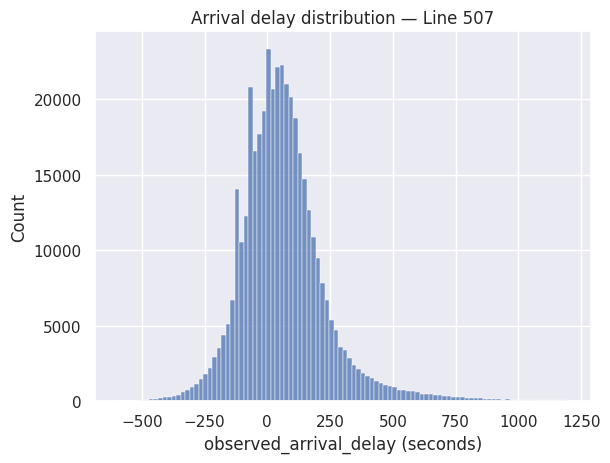

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set()

d = line_df['observed_arrival_delay'].dropna()
sns.histplot(x=d[(d > -600) & (d < 1200)], bins=100)
plt.title("Arrival delay distribution — Line 507")
plt.xlabel("observed_arrival_delay (seconds)")
plt.show()

In [ ]:
line_df['observed_arrival_delay'].describe()

,observed_arrival_delay
count,418313.000000
mean,71.692302
std,222.363058
min,-4870.000000
25%,-44.000000
50%,48.000000
75%,144.000000
max,6806.000000


## Section 4: Cleaning and Feature Engineering

### 4.1. Cleaning

In [ ]:
clean = line_df.copy()
n0 = len(clean)

# 1. Drop missing arrival delay
clean = clean[clean['observed_arrival_delay'].notna()]
n1 = len(clean)

# 2. Drop physically impossible delays (noise)
clean = clean[(clean['observed_arrival_delay'] >= -600)]
n2 = len(clean)

print(f"Start:           {n0:,}")
print(f"After missing:   {n1:,}  (-{n0-n1:,})")
print(f"After noise:     {n2:,}  (-{n1-n2:,})")
print(f"Kept: {n2/n0*100:.1f}%")

NameError: name 'line_df' is not defined

### 4.2. Time features

In [ ]:
import numpy as np

clean['date'] = pd.to_datetime(clean['date'], format='%Y%m%d')
clean['hour'] = (clean['scheduled_arrival_time_sfm'] // 3600) % 24
clean['weekday'] = clean['date'].dt.dayofweek        # 0=Mon, 6=Sun
clean['is_weekend'] = (clean['weekday'] >= 5).astype(int)
clean['month'] = clean['date'].dt.month

def peak(h):
    if 6 <= h <= 9:   return 'morning_peak'
    if 16 <= h <= 19: return 'afternoon_peak'
    return 'off_peak'
clean['period'] = clean['hour'].apply(peak)

# Cyclical hour
clean['hour_sin'] = np.sin(2 * np.pi * clean['hour'] / 24)
clean['hour_cos'] = np.cos(2 * np.pi * clean['hour'] / 24)

### 4.3. Upstream delay features

In [ ]:
# Sort so each run is in stop order
clean = clean.sort_values(['trip_id', 'date', 'stop_sequence'])

grp = clean.groupby(['trip_id', 'date'])

# Previous row's delay and its stop_sequence
prev_delay = grp['observed_arrival_delay'].shift(1)
prev_seq   = grp['stop_sequence'].shift(1)

# Only valid if the previous row is the physically adjacent stop
is_consecutive = (clean['stop_sequence'] - prev_seq) == 1
clean['upstream_delay'] = prev_delay.where(is_consecutive)

# Same for two stops back (must be exactly 2 apart)
prev_delay_2 = grp['observed_arrival_delay'].shift(2)
prev_seq_2   = grp['stop_sequence'].shift(2)
is_consecutive_2 = (clean['stop_sequence'] - prev_seq_2) == 2
clean['upstream_delay_2'] = prev_delay_2.where(is_consecutive_2)

# Check how many valid upstream values we got
print("upstream_delay valid:",   clean['upstream_delay'].notna().sum())
print("upstream_delay NaN:",      clean['upstream_delay'].isna().sum())
print("upstream_delay_2 valid:",  clean['upstream_delay_2'].notna().sum())

upstream_delay valid: 389686
upstream_delay NaN: 28439
upstream_delay_2 valid: 361270


## Section 5: Modelling

### Train / Test Split

In [ ]:
features = ['hour','weekday','is_weekend','month','hour_sin','hour_cos',
            'stop_sequence','dist_traveled','upstream_delay']

target = 'observed_arrival_delay'

model_df = clean.dropna(subset=['upstream_delay']).copy()
model_df['date'] = pd.to_datetime(model_df['date'])

model_df = model_df.sort_values(['date','trip_id','stop_sequence']).reset_index(drop=True)

train_df = model_df[model_df['date'] < '2024-10-01']
val_df   = model_df[(model_df['date'] >= '2024-10-01') & (model_df['date'] < '2024-11-01')]
test_df  = model_df[model_df['date'] >= '2024-11-01']

X_train, y_train = train_df[features], train_df[target]
X_val,   y_val   = val_df[features],   val_df[target]
X_test,  y_test  = test_df[features],  test_df[target]

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)

Train: (290947, 9) | Val: (34598, 9) | Test: (64141, 9)


###Model 1: Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

lr = LinearRegression()

lr.fit(X_train, y_train)

pred_lr_val = lr.predict(X_val)

lr_val_mae = mean_absolute_error(y_val, pred_lr_val)
lr_val_rmse = np.sqrt(
    mean_squared_error(y_val, pred_lr_val)
)
lr_val_r2 = r2_score(y_val, pred_lr_val)

print("Linear Regression — October Validation")
print(f"MAE:  {lr_val_mae:.2f} s")
print(f"RMSE: {lr_val_rmse:.2f} s")
print(f"R²:   {lr_val_r2:.4f}")

Linear Regression — October Validation
MAE:  55.34 s
RMSE: 82.00 s
R²:   0.8802


###Model 2: Random Forest Regressor

In [ ]:
import numpy as np

rf_cv_splits = []

fold_definitions = [
    {
        "train_end": 6,
        "val_month": 7
    },
    {
        "train_end": 7,
        "val_month": 8
    },
    {
        "train_end": 8,
        "val_month": 9
    }
]

for fold in fold_definitions:

    train_idx = np.where(
        train_df['month'] <= fold["train_end"]
    )[0]

    val_idx = np.where(
        train_df['month'] == fold["val_month"]
    )[0]

    rf_cv_splits.append(
        (train_idx, val_idx)
    )

    print(
        f"Train Jan–{fold['train_end']:02d}: "
        f"{len(train_idx):,} | "
        f"Validate {fold['val_month']:02d}: "
        f"{len(val_idx):,}"
    )

Train Jan–06: 193,113 | Validate 07: 31,105
Train Jan–07: 224,218 | Validate 08: 33,707
Train Jan–08: 257,925 | Validate 09: 33,022


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

rf_param_distributions = {
    "n_estimators": [100, 150, 200, 300],
    "max_depth": [10, 15, 20, 25, None],
    "min_samples_leaf": [1, 3, 5, 10],
    "max_features": ["sqrt", 0.7, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=rf_param_distributions,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=rf_cv_splits,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=False
)

rf_search.fit(
    X_train,
    y_train
)

rf_best_params = rf_search.best_params_

print("Best RF parameters:")
print(rf_best_params)

print(
    "Best chronological CV MAE:",
    -rf_search.best_score_
)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best RF parameters:
{'n_estimators': 100, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': 25}
Best chronological CV MAE: 39.235045812622616


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Reconstruct the RF selected by chronological CV
best_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=25,
    max_features=0.7,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

# Fit using January–September training data
best_rf.fit(X_train, y_train)

print("Final specialized Random Forest fitted.")
print(best_rf)

Final specialized Random Forest fitted.
RandomForestRegressor(max_depth=25, max_features=0.7, min_samples_leaf=10,
                      n_jobs=-1, random_state=42)


In [ ]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pred_rf_val = best_rf.predict(X_val)

rf_val_mae = mean_absolute_error(y_val, pred_rf_val)
rf_val_rmse = np.sqrt(mean_squared_error(y_val, pred_rf_val))
rf_val_r2 = r2_score(y_val, pred_rf_val)

print("Random Forest — October Validation")
print(f"MAE:  {rf_val_mae:.2f} s")
print(f"RMSE: {rf_val_rmse:.2f} s")
print(f"R²:   {rf_val_r2:.4f}")

Random Forest — October Validation
MAE:  32.22 s
RMSE: 58.77 s
R²:   0.9385


### Model 3: XGBoost

In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

xgb_param_distributions = {
    "n_estimators": [150, 200, 300, 400],
    "max_depth": [3, 4, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=XGBRegressor(
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ),
    param_distributions=xgb_param_distributions,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=rf_cv_splits,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=False
)

xgb_search.fit(
    X_train,
    y_train
)

xgb_best_params = xgb_search.best_params_

print("Best XGBoost parameters:")
print(xgb_best_params)

print(
    "Best chronological CV MAE:",
    -xgb_search.best_score_
)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best XGBoost parameters:
{'subsample': 1.0, 'n_estimators': 150, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Best chronological CV MAE: 42.435741245010576


In [ ]:
xgb_best = XGBRegressor(
    **xgb_best_params,
    random_state=42,
    n_jobs=-1,
    objective="reg:squarederror"
)

xgb_best.fit(
    X_train,
    y_train
)

pred_xgb_val = xgb_best.predict(X_val)

xgb_val_mae = mean_absolute_error(
    y_val,
    pred_xgb_val
)

xgb_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        pred_xgb_val
    )
)

xgb_val_r2 = r2_score(
    y_val,
    pred_xgb_val
)

print("XGBoost — October Validation")
print(f"MAE:  {xgb_val_mae:.2f} s")
print(f"RMSE: {xgb_val_rmse:.2f} s")
print(f"R²:   {xgb_val_r2:.4f}")

XGBoost — October Validation
MAE:  40.68 s
RMSE: 90.52 s
R²:   0.8540


###Model 4: Neural Network

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print("Scaled:", X_train_s.shape)

Scaled: (290947, 9)


In [ ]:
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

def build_nn(
    hidden_units=(128, 64),
    learning_rate=0.001,
    dropout=0.0
):

    model = keras.Sequential()

    model.add(
        layers.Input(
            shape=(len(features),)
        )
    )

    for units in hidden_units:

        model.add(
            layers.Dense(
                units,
                activation="relu"
            )
        )

        if dropout > 0:
            model.add(
                layers.Dropout(dropout)
            )

    model.add(
        layers.Dense(1)
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mae",
        metrics=["mae"]
    )

    return model

NN randomized search

In [ ]:
from sklearn.model_selection import ParameterSampler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

import pandas as pd
import numpy as np
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

nn_param_distributions = {

    "hidden_units": [
        (32, 16),
        (64, 32),
        (128, 64),
        (128, 128),
        (256, 128)
    ],

    "learning_rate": [
        0.0001,
        0.0005,
        0.001
    ],

    "batch_size": [
        128,
        256,
        512
    ],

    "dropout": [
        0.0,
        0.1,
        0.2
    ]
}

nn_candidates = list(
    ParameterSampler(
        nn_param_distributions,
        n_iter=10,
        random_state=42
    )
)

print(
    "NN candidates:",
    len(nn_candidates)
)

NN candidates: 10


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

nn_search_results = []

for candidate_id, params in enumerate(
    nn_candidates,
    start=1
):

    print()
    print("=" * 60)
    print(
        f"Candidate "
        f"{candidate_id}/{len(nn_candidates)}"
    )
    print(params)

    fold_maes = []

    for fold_id, (
        train_idx,
        val_idx
    ) in enumerate(
        rf_cv_splits,
        start=1
    ):

        # --------------------------------
        # Fold datasets
        # --------------------------------

        X_fold_train = (
            X_train.iloc[train_idx]
        )

        y_fold_train = (
            y_train.iloc[train_idx]
        )

        X_fold_val = (
            X_train.iloc[val_idx]
        )

        y_fold_val = (
            y_train.iloc[val_idx]
        )


        # --------------------------------
        # Fold-specific scaler
        # --------------------------------

        fold_scaler = StandardScaler()

        X_fold_train_s = (
            fold_scaler
            .fit_transform(X_fold_train)
            .astype(np.float32)
        )

        X_fold_val_s = (
            fold_scaler
            .transform(X_fold_val)
            .astype(np.float32)
        )


        # --------------------------------
        # Build model
        # --------------------------------

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(
            42 + candidate_id + fold_id
        )

        model = build_nn(
            hidden_units=params[
                "hidden_units"
            ],
            learning_rate=float(
                params["learning_rate"]
            ),
            dropout=float(
                params["dropout"]
            )
        )


        # --------------------------------
        # Early stopping
        # --------------------------------

        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True
        )


        # --------------------------------
        # Train
        # --------------------------------

        model.fit(
            X_fold_train_s,
            y_fold_train,
            validation_data=(
                X_fold_val_s,
                y_fold_val
            ),
            epochs=100,
            batch_size=int(
                params["batch_size"]
            ),
            callbacks=[
                early_stop
            ],
            verbose=0,
            shuffle=True
        )


        # --------------------------------
        # Evaluate fold
        # --------------------------------

        pred = (
            model.predict(
                X_fold_val_s,
                verbose=0
            )
            .reshape(-1)
        )

        fold_mae = mean_absolute_error(
            y_fold_val,
            pred
        )

        fold_maes.append(
            fold_mae
        )

        print(
            f"Fold {fold_id}: "
            f"MAE = {fold_mae:.2f} s"
        )


    mean_cv_mae = np.mean(
        fold_maes
    )

    result = {
        **params,
        "fold_1_mae": fold_maes[0],
        "fold_2_mae": fold_maes[1],
        "fold_3_mae": fold_maes[2],
        "mean_cv_mae": mean_cv_mae
    }

    nn_search_results.append(
        result
    )

    print(
        f"Mean CV MAE: "
        f"{mean_cv_mae:.2f} s"
    )


Candidate 1/10
{'learning_rate': 0.001, 'hidden_units': (128, 64), 'dropout': 0.0, 'batch_size': 512}
Fold 1: MAE = 33.41 s
Fold 2: MAE = 35.10 s
Fold 3: MAE = 51.09 s
Mean CV MAE: 39.86 s

Candidate 2/10
{'learning_rate': 0.0005, 'hidden_units': (128, 64), 'dropout': 0.1, 'batch_size': 256}
Fold 1: MAE = 32.58 s
Fold 2: MAE = 33.74 s
Fold 3: MAE = 50.93 s
Mean CV MAE: 39.08 s

Candidate 3/10
{'learning_rate': 0.0001, 'hidden_units': (32, 16), 'dropout': 0.1, 'batch_size': 512}
Fold 1: MAE = 42.58 s
Fold 2: MAE = 42.40 s
Fold 3: MAE = 53.56 s
Mean CV MAE: 46.18 s

Candidate 4/10
{'learning_rate': 0.0005, 'hidden_units': (64, 32), 'dropout': 0.1, 'batch_size': 128}
Fold 1: MAE = 34.51 s
Fold 2: MAE = 34.68 s
Fold 3: MAE = 49.73 s
Mean CV MAE: 39.64 s

Candidate 5/10
{'learning_rate': 0.0001, 'hidden_units': (256, 128), 'dropout': 0.2, 'batch_size': 128}
Fold 1: MAE = 38.15 s
Fold 2: MAE = 37.62 s
Fold 3: MAE = 51.02 s
Mean CV MAE: 42.26 s

Candidate 6/10
{'learning_rate': 0.001, 'hidde

In [ ]:
nn_search_df = pd.DataFrame(
    nn_search_results
)

nn_search_df = (
    nn_search_df
    .sort_values("mean_cv_mae")
    .reset_index(drop=True)
)

display(nn_search_df)

nn_best_params = {
    "hidden_units":
        nn_search_df.loc[
            0,
            "hidden_units"
        ],

    "learning_rate":
        nn_search_df.loc[
            0,
            "learning_rate"
        ],

    "batch_size":
        nn_search_df.loc[
            0,
            "batch_size"
        ],

    "dropout":
        nn_search_df.loc[
            0,
            "dropout"
        ]
}

print(
    "Best NN hyperparameters:"
)

print(
    nn_best_params
)

print(
    "Best CV MAE:",
    nn_search_df.loc[
        0,
        "mean_cv_mae"
    ]
)

,learning_rate,hidden_units,dropout,batch_size,fold_1_mae,fold_2_mae,fold_3_mae,mean_cv_mae
0,0.0010,"(128, 64)",0.2,512,32.055245,32.309368,50.912585,38.425733
1,0.0005,"(128, 64)",0.1,256,32.584442,33.738765,50.926579,39.083262
2,0.0005,"(64, 32)",0.1,128,34.513364,34.681984,49.727334,39.640894
3,0.0010,"(128, 64)",0.0,512,33.407830,35.100499,51.085823,39.864717
4,0.0010,"(64, 32)",0.1,512,35.951469,34.157308,51.217907,40.442228
5,0.0010,"(64, 32)",0.2,512,36.301380,36.489067,51.683893,41.491446
6,0.0001,"(256, 128)",0.2,128,38.152059,37.618365,51.021879,42.264101
7,0.0001,"(256, 128)",0.0,128,38.233251,38.580084,51.218175,42.677170
8,0.0010,"(32, 16)",0.1,256,37.891026,42.017735,52.126403,44.011721
9,0.0001,"(32, 16)",0.1,512,42.584392,42.395368,53.558213,46.179324


Best NN hyperparameters:
{'hidden_units': (128, 64), 'learning_rate': np.float64(0.001), 'batch_size': np.int64(512), 'dropout': np.float64(0.2)}
Best CV MAE: 38.42573269458168


In [ ]:
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping

# -------------------------------------
# Jan–Aug model fitting
# September early stopping
# -------------------------------------

nn_fit_mask = (
    train_df["month"] < 9
)

nn_stop_mask = (
    train_df["month"] == 9
)

X_nn_fit = train_df.loc[
    nn_fit_mask,
    features
]

y_nn_fit = train_df.loc[
    nn_fit_mask,
    target
]

X_nn_stop = train_df.loc[
    nn_stop_mask,
    features
]

y_nn_stop = train_df.loc[
    nn_stop_mask,
    target
]


# -------------------------------------
# Final fitted scaler
# -------------------------------------

nn_scaler = StandardScaler()

X_nn_fit_s = (
    nn_scaler
    .fit_transform(X_nn_fit)
    .astype(np.float32)
)

X_nn_stop_s = (
    nn_scaler
    .transform(X_nn_stop)
    .astype(np.float32)
)


# -------------------------------------
# Build final NN
# -------------------------------------

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

best_nn = build_nn(
    hidden_units=nn_best_params[
        "hidden_units"
    ],
    learning_rate=float(
        nn_best_params[
            "learning_rate"
        ]
    ),
    dropout=float(
        nn_best_params[
            "dropout"
        ]
    )
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = best_nn.fit(
    X_nn_fit_s,
    y_nn_fit,
    validation_data=(
        X_nn_stop_s,
        y_nn_stop
    ),
    epochs=100,
    batch_size=int(
        nn_best_params[
            "batch_size"
        ]
    ),
    callbacks=[
        early_stop
    ],
    verbose=1
)

Epoch 1/100
504/504 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 76.5245 - mae: 76.5245 - val_loss: 57.0626 - val_mae: 57.0626
Epoch 2/100
504/504 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 47.0287 - mae: 47.0287 - val_loss: 55.2993 - val_mae: 55.2993
Epoch 3/100
504/504 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 45.9193 - mae: 45.9193 - val_loss: 53.8722 - val_mae: 53.8722
Epoch 4/100
504/504 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 45.2739 - mae: 45.2739 - val_loss: 53.0829 - val_mae: 53.0829
Epoch 5/100
504/504 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 44.9601 - mae: 44.9601 - val_loss: 52.6911 - val_mae: 52.6911
Epoch 6/100
504/504 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 44.6597 - mae: 44.6597 - val_loss: 52.0816 - val_mae: 52.0816
Epoch 7/100
504/504 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 44.4816 - mae: 44.4816 - val_loss: 51.8246 - val_mae: 51.8246
Epoch 8/100
504/504 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 44.3445 - mae: 44.3445 - val_loss: 51.6416 - val_mae: 51.6416
Epoch 9/100
504/

Validation

In [ ]:
X_val_nn_s = (
    nn_scaler
    .transform(X_val)
    .astype(np.float32)
)

pred_nn_val = (
    best_nn
    .predict(
        X_val_nn_s,
        verbose=0
    )
    .reshape(-1)
)

nn_val_mae = mean_absolute_error(
    y_val,
    pred_nn_val
)

nn_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        pred_nn_val
    )
)

nn_val_r2 = r2_score(
    y_val,
    pred_nn_val
)

print(
    "Neural Network "
    "— October Validation"
)

print(
    f"MAE:  "
    f"{nn_val_mae:.2f} s"
)

print(
    f"RMSE: "
    f"{nn_val_rmse:.2f} s"
)

print(
    f"R²:   "
    f"{nn_val_r2:.4f}"
)

Neural Network — October Validation
MAE:  53.22 s
RMSE: 80.98 s
R²:   0.8831


### Results

In [ ]:
import pandas as pd

validation_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost",
        "Neural Network"
    ],

    "MAE (s)": [
        55.34,
        32.22,
        40.68,
        53.22
    ],

    "RMSE (s)": [
        82.00,
        58.77,
        90.52,
        80.98
    ],

    "R²": [
        0.8802,
        0.9385,
        0.8540,
        0.8831
    ]
})

validation_results = (
    validation_results
    .sort_values("MAE (s)")
    .reset_index(drop=True)
)

display(validation_results)

best_specialized_name = validation_results.iloc[0]["Model"]

print("\nSelected specialized model:", best_specialized_name)
print(
    "October validation MAE:",
    validation_results.iloc[0]["MAE (s)"]
)

,Model,MAE (s),RMSE (s),R²
0,Random Forest,32.22,58.77,0.9385
1,XGBoost,40.68,90.52,0.8540
2,Neural Network,53.22,80.98,0.8831
3,Linear Regression,55.34,82.00,0.8802



Selected specialized model: Random Forest
October validation MAE: 32.22


In [ ]:
import os
import json
import joblib

# --------------------------------------------------
# Paths
# --------------------------------------------------

PROJECT_PATH = "/content/drive/MyDrive/Project AI in Transportation"
MODELS_PATH = f"{PROJECT_PATH}/models"
SPECIALIZED_MODEL_PATH = f"{MODELS_PATH}/specialized"

os.makedirs(
    SPECIALIZED_MODEL_PATH,
    exist_ok=True
)

# --------------------------------------------------
# 1. Save selected specialized model
# --------------------------------------------------

joblib.dump(
    best_rf,
    f"{SPECIALIZED_MODEL_PATH}/line507_random_forest.joblib"
)

# --------------------------------------------------
# 2. Save exact feature names and order
# --------------------------------------------------

joblib.dump(
    features,
    f"{SPECIALIZED_MODEL_PATH}/line507_features.joblib"
)

# --------------------------------------------------
# 3. Save hyperparameters and model-selection info
# --------------------------------------------------

model_info = {
    "model": "RandomForestRegressor",
    "line_id": "9011001050700000",

    "selection_metric": "MAE",
    "selection_period": "October 2024 validation",

    "validation_results": {
        "MAE_seconds": 32.22,
        "RMSE_seconds": 58.77,
        "R2": 0.9385
    },

    "training_period": "January-September 2024",

    "hyperparameters": best_rf.get_params(),

    "features": list(features),

    "scaler_required": False
}

with open(
    f"{SPECIALIZED_MODEL_PATH}/line507_rf_model_info.json",
    "w"
) as f:
    json.dump(
        model_info,
        f,
        indent=4,
        default=str
    )

# --------------------------------------------------
# Confirmation
# --------------------------------------------------

print("Specialized Line 507 model saved successfully!")
print("\nLocation:")
print(SPECIALIZED_MODEL_PATH)

print("\nSaved files:")
for file in sorted(
    os.listdir(SPECIALIZED_MODEL_PATH)
):
    print(" -", file)

Specialized Line 507 model saved successfully!

Location:
/content/drive/MyDrive/Project AI in Transportation/models/specialized

Saved files:
 - line507_features.joblib
 - line507_random_forest.joblib
 - line507_rf_model_info.json
